# Singapore GP Pit Strategy Sim

**When Does a Two-Stop Beat a One-Stop at the Singapore Grand Prix?**

A stochastic Monte Carlo and discrete-time Markov chain (DTMC) race strategy simulator for the 62-lap Singapore Grand Prix at Marina Bay Street Circuit. This notebook calibrates a tyre degradation and lap-time model against real 2023–2024 Singapore Grand Prix race data via FastF1, models Safety Car deployments as a two-state Markov chain, and sweeps pit-stop time loss (15–30 s) against Safety Car probability to determine the break-even strategy threshold with 95% confidence intervals.

## 1. Problem and Question

At Marina Bay Street Circuit, overtaking difficulty and high pit-lane time loss historically favored one-stop strategies. In 2025, raising the Singapore pit-lane speed limit reduced pit-stop time loss from roughly 28 s to 21 s, yet teams still largely committed to one-stop strategies. Meanwhile, Marina Bay has historically featured frequent Safety Car periods (at least one in every edition from 2008 to 2023, followed by zero in 2024 and 2025).

**Research Question:** How small must the green-flag pit-stop time loss be before a two-stop strategy beats a one-stop strategy on expected 62-lap race time at Marina Bay, and how does the per-lap probability of a Safety Car shift that break-even threshold?

## 2. Model, Assumptions, and Equations

### 2.1 Lap-Time and Tyre Degradation Model (Input Modelling & Random Variate Generation)
For lap $t \in \{1, \dots, 62\}$ on tyre compound $c \in \{\text{SOFT}, \text{MEDIUM}, \text{HARD}\}$ with tyre age $a_t \ge 1$ (laps completed on the current set), the green-flag lap time $T_t$ (in seconds) is:
$$T_t = T_{\text{base}} + \Delta_c + \beta_c (a_t - 1) + \varepsilon_t, \quad \varepsilon_t \sim \mathcal{N}(0, \sigma^2)$$
where:
- $T_{\text{base}}$ (s): baseline reference lap pace on the reference compound (`HARD` at $a_t = 1$),
- $\Delta_c$ (s): compound pace offset relative to `HARD` ($\Delta_{\text{HARD}} = 0$),
- $\beta_c$ (s/lap): linear tyre degradation rate for compound $c$,
- $\sigma$ (s): lap-to-lap stochastic noise standard deviation.

### 2.2 Two-State Markov Safety Car Model (Discrete-Time Markov Chain)
Race neutralization on lap $t$ is modeled as a homogeneous two-state DTMC $S_t \in \{0 \text{ (Green)}, 1 \text{ (Safety Car)}\}$ with transition matrix:
$$P = \begin{pmatrix} 1 - p_{01} & p_{01} \\ p_{10} & 1 - p_{10} \end{pmatrix}$$
where $p_{01} = P(S_{t+1}=1 \mid S_t=0)$ is the per-lap probability of a Safety Car deployment from green-flag racing, and $p_{10} = P(S_{t+1}=0 \mid S_t=1) = 1 / L_{\text{SC}}$ governs expected Safety Car duration $L_{\text{SC}}$ (laps). The stationary Safety Car probability is:
$$\pi_1 = \frac{p_{01}}{p_{01} + p_{10}}$$
During a Safety Car lap ($S_t = 1$), field pace is neutralized to $T_{\text{SC}}$ (s) and the effective pit-stop loss is discounted by factor $\alpha \in (0, 1)$: $L_{\text{pit}}(S_t) = L_{\text{pit}} \cdot (1 - \alpha \mathbb{I}\{S_t = 1\})$.

### 2.3 Monte Carlo Race Estimator (Law of Large Numbers)
For strategy $\mathcal{S}$ and $N$ independent Monte Carlo replications, total race time $R^{(i)}(\mathcal{S})$ is averaged via $\bar{R}_N(\mathcal{S}) = \frac{1}{N} \sum_{i=1}^N R^{(i)}(\mathcal{S})$ with 95% confidence interval $\bar{R}_N \pm 1.96 \frac{s_N}{\sqrt{N}}$.

## 4. Implementation

We install dependencies, load the empirical 2023–2025 Singapore GP dataset, calibrate the fuel- and driver-adjusted OLS model, and implement the vectorized CRN Monte Carlo + DTMC race simulator.

In [1]:
# Cell 1: Dependencies (uncomment pip install if running in a fresh environment)
!pip install -q fastf1 numpy pandas scipy matplotlib statsmodels

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats

from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
DATA_DIR = PROJECT_ROOT / "data"
FIGURES_DIR = PROJECT_ROOT / "figures"

SEED = 42
rng = np.random.default_rng(SEED)
print(f"Initialized RNG with seed={SEED}")

Initialized RNG with seed=42


In [2]:
# Cell 2: Load 2023–2024 Singapore GP race laps via FastF1 (with local CSV caching/fallback)
DATA_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
LOCAL_CSV = DATA_DIR / "singapore_2023_2024_2025_clean_laps.csv"

def fetch_and_clean_singapore_laps(years=(2023, 2024, 2025), cache_dir=str(PROJECT_ROOT / ".fastf1_cache")):
    import fastf1
    os.makedirs(cache_dir, exist_ok=True)
    fastf1.Cache.enable_cache(cache_dir)
    frames = []
    for year in years:
        for attempt in range(1, 4):
            try:
                session = fastf1.get_session(year, "Singapore", "R")
                session.load(laps=True, telemetry=False, weather=False, messages=False)
                laps = session.laps.copy()
                if laps is None or len(laps) == 0:
                    raise ValueError(f"Empty laps for {year}")
                laps["Season"] = year
                frames.append(laps)
                print(f"Loaded {year} Singapore GP ({len(laps)} raw laps)")
                break
            except Exception as exc:
                print(f"Attempt {attempt} failed for {year}: {type(exc).__name__}: {exc}")
                time.sleep(2 * attempt)
    if not frames:
        return None
    raw = pd.concat(frames, ignore_index=True)
    raw["LapTime_s"] = raw["LapTime"].dt.total_seconds()
    raw["TrackStatus_str"] = raw["TrackStatus"].astype(str).str.strip()
    clean = raw[
        (raw["TrackStatus_str"] == "1")
        & (raw["PitInTime"].isna())
        & (raw["PitOutTime"].isna())
        & (raw["LapTime_s"].notna())
        & (raw["TyreLife"].notna())
        & (raw["Compound"].isin(["SOFT", "MEDIUM", "HARD"]))
        & (raw["LapNumber"].between(1, 62))
    ].copy()
    med = clean.groupby("Season")["LapTime_s"].transform("median")
    clean = clean[clean["LapTime_s"] <= 1.07 * med].copy()
    keep_cols = ["Season", "Driver", "Team", "LapNumber", "Stint", "Compound", "TyreLife", "LapTime_s"]
    return clean[keep_cols]

GITHUB_RAW_CSV = "https://raw.githubusercontent.com/HelinduS/singapore-gp-pit-strategy-sim/main/data/singapore_2023_2024_2025_clean_laps.csv"

if LOCAL_CSV.exists():
    clean_laps = pd.read_csv(LOCAL_CSV)
    print(f"Loaded cached dataset from data/{LOCAL_CSV.name} ({len(clean_laps)} clean laps).")
else:
    clean_laps = None
    try:
        clean_laps = pd.read_csv(GITHUB_RAW_CSV)
        clean_laps.to_csv(LOCAL_CSV, index=False)
        print(f"Downloaded dataset from GitHub ({len(clean_laps)} clean laps).")
    except Exception:
        clean_laps = fetch_and_clean_singapore_laps()
        if clean_laps is not None and len(clean_laps) > 0:
            clean_laps.to_csv(LOCAL_CSV, index=False)
            print(f"Saved {len(clean_laps)} clean laps to data/{LOCAL_CSV.name}.")
        else:
            raise RuntimeError("Unable to load dataset from local cache, GitHub, or FastF1.")

Loaded cached dataset from data/singapore_2023_2024_2025_clean_laps.csv (3074 clean laps).


In [3]:
# Cell 3: Fuel- and Driver-Adjusted OLS Calibration (2023–2025 Singapore GP)
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

# Exclude Lap 1 (standing start traffic/acceleration) and ensure clean copy
df_fit = clean_laps[clean_laps["LapNumber"] >= 2].copy()
df_fit["TyreAge0"] = df_fit["TyreLife"] - 1.0
df_fit["DriverSeason"] = df_fit["Season"].astype(str) + "_" + df_fit["Driver"].astype(str)

# Regress lap time on Driver-Season pace, fuel burn (LapNumber), compound offsets, and compound-specific wear
ols_fit = smf.ols(
    "LapTime_s ~ C(DriverSeason) + LapNumber + C(Compound, Treatment(reference='HARD')) * TyreAge0",
    data=df_fit,
).fit()

params = ols_fit.params

# Extract key physical parameters (excluding nuisance driver-season intercepts)
key_terms = [k for k in params.index if not k.startswith("C(DriverSeason)")]
summary_df = pd.DataFrame({
    "coef": ols_fit.params[key_terms],
    "std_err": ols_fit.bse[key_terms],
    "t": ols_fit.tvalues[key_terms],
    "p_value": ols_fit.pvalues[key_terms],
})
print(f"Adjusted OLS | n={len(df_fit)} laps | R2={ols_fit.rsquared:.4f} | Residual sigma={np.std(ols_fit.resid, ddof=1):.4f} s\n")
print(summary_df.to_string(float_format=lambda x: f"{x:8.4f}"))

# Representative 2025 front-runner baseline pace at Lap 1 on fresh HARD tyres
# (Using median 2025 driver-season intercept shift + global Intercept)
ds_2025 = [k for k in params.index if k.startswith("C(DriverSeason)[T.2025_")]
median_2025_shift = float(np.median([params[k] for k in ds_2025])) if ds_2025 else 0.0

T_BASE = float(params["Intercept"] + median_2025_shift)
FUEL_EFFECT = float(params["LapNumber"])  # Expected negative (~ -0.05 to -0.08 s/lap)

DELTA = {
    "HARD": 0.0,
    "MEDIUM": float(params.get("C(Compound, Treatment(reference='HARD'))[T.MEDIUM]", -0.45)),
    "SOFT": float(params.get("C(Compound, Treatment(reference='HARD'))[T.SOFT]", -0.90)),
}

beta_hard = float(params["TyreAge0"])
BETA = {
    "HARD": beta_hard,
    "MEDIUM": beta_hard + float(params.get("C(Compound, Treatment(reference='HARD'))[T.MEDIUM]:TyreAge0", 0.0)),
    "SOFT": beta_hard + float(params.get("C(Compound, Treatment(reference='HARD'))[T.SOFT]:TyreAge0", 0.0)),
}
SIGMA = float(np.std(ols_fit.resid, ddof=1))

print("\n--- Extracted Physical Model Parameters ---")
print(f"T_BASE (2025 median ref, Lap 0, fresh HARD): {T_BASE:.3f} s")
print(f"FUEL_EFFECT (per lap burned):                {FUEL_EFFECT:.4f} s/lap")
print(f"DELTA (compound offset vs HARD):             { {k: round(v, 4) for k, v in DELTA.items()} }")
print(f"BETA  (tyre degradation s/lap):              { {k: round(v, 4) for k, v in BETA.items()} }")
print(f"SIGMA (within-driver lap noise):             {SIGMA:.4f} s")

Adjusted OLS | n=3068 laps | R2=0.7089 | Residual sigma=0.8853 s

                                                                coef  std_err        t  p_value
Intercept                                                   101.8020   0.1416 718.9432   0.0000
C(Compound, Treatment(reference='HARD'))[T.MEDIUM]           -0.2980   0.0663  -4.4961   0.0000
C(Compound, Treatment(reference='HARD'))[T.SOFT]             -0.2602   0.1099  -2.3683   0.0179
LapNumber                                                    -0.0504   0.0013 -38.4850   0.0000
TyreAge0                                                      0.0521   0.0026  19.8058   0.0000
C(Compound, Treatment(reference='HARD'))[T.MEDIUM]:TyreAge0  -0.0056   0.0036  -1.5312   0.1258
C(Compound, Treatment(reference='HARD'))[T.SOFT]:TyreAge0    -0.0255   0.0078  -3.2845   0.0010

--- Extracted Physical Model Parameters ---
T_BASE (2025 median ref, Lap 0, fresh HARD): 99.065 s
FUEL_EFFECT (per lap burned):                -0.0504 s/lap
DELTA (c

In [4]:
# Cell 4: Core 62-Lap Race Simulator (CRN Markov Safety Car + Optimal Pit-Lap Search)
TOTAL_LAPS = 62
T_SC = 132.0            # Neutralized Safety Car lap time (s)
SC_PIT_DISCOUNT = 0.50  # 50% pit-loss discount under Safety Car (~21s -> ~10.5s)
L_SC_MEAN = 4.0         # Mean Safety Car duration (laps) -> p_10 = 0.25


def deterministic_race_time(
    pit_laps,
    compounds,
    pit_loss_s,
    t_base=T_BASE,
    fuel_effect=FUEL_EFFECT,
    delta=DELTA,
    beta=BETA,
):
    """Exact deterministic green-flag race time (sigma=0, p_sc=0)."""
    pit_set = set(pit_laps)
    stint_idx = 0
    tyre_age = 0
    total = 0.0
    for lap in range(1, TOTAL_LAPS + 1):
        c = compounds[stint_idx]
        total += t_base + fuel_effect * lap + delta[c] + beta[c] * tyre_age
        if lap in pit_set:
            total += pit_loss_s
            stint_idx += 1
            tyre_age = 0
        else:
            tyre_age += 1
    return total


def find_optimal_pit_laps():
    """Grid search for optimal green-flag pit laps (1-stop M->H, 2-stop M->M->H)."""
    best_1_lap, best_1_t = min(
        ((p, deterministic_race_time([p], ["MEDIUM", "HARD"], 0.0)) for p in range(10, 53)),
        key=lambda x: x[1],
    )
    best_2_laps, best_2_t = min(
        (
            ((p1, p2), deterministic_race_time([p1, p2], ["MEDIUM", "MEDIUM", "HARD"], 0.0))
            for p1 in range(10, 38)
            for p2 in range(p1 + 10, 54)
        ),
        key=lambda x: x[1],
    )
    return [best_1_lap], list(best_2_laps), best_1_t - best_2_t


OPT_1_LAPS, OPT_2_LAPS, DET_BREAKEVEN = find_optimal_pit_laps()
ONE_STOP = (OPT_1_LAPS, ["MEDIUM", "HARD"])
TWO_STOP = (OPT_2_LAPS, ["MEDIUM", "MEDIUM", "HARD"])
print(f"Optimal green-flag 1-stop (M->H):   pit lap {OPT_1_LAPS}")
print(f"Optimal green-flag 2-stop (M->M->H): pit laps {OPT_2_LAPS}")
print(f"Deterministic green-flag break-even pit loss: {DET_BREAKEVEN:.2f} s")


def generate_sc_scenarios(p_sc_deploy, n_sims=3000, seed=42):
    """Simulate n_sims trajectories of the 2-state DTMC (0=Green, 1=Safety Car)."""
    local_rng = np.random.default_rng(seed)
    p_10 = 1.0 / L_SC_MEAN
    sc_matrix = np.zeros((n_sims, TOTAL_LAPS), dtype=np.int8)
    u = local_rng.random((n_sims, TOTAL_LAPS))
    state = np.zeros(n_sims, dtype=np.int8)

    for lap in range(1, TOTAL_LAPS + 1):
        idx = lap - 1
        if lap > 1 and p_sc_deploy > 0.0:
            to_sc = (state == 0) & (u[:, idx] < p_sc_deploy)
            to_green = (state == 1) & (u[:, idx] < p_10)
            state = np.where(to_sc, 1, np.where(to_green, 0, state))
        sc_matrix[:, idx] = state
    return sc_matrix


def simulate_strategy_on_scenarios(
    target_pits,
    compounds,
    pit_loss_s,
    sc_matrix,
    sigma=SIGMA,
    sc_window=8,
    sc_discount=SC_PIT_DISCOUNT,
    t_base=T_BASE,
    fuel_effect=FUEL_EFFECT,
    delta=DELTA,
    beta=BETA,
    noise_seed=100,
):
    """
    Vectorized 62-lap race simulation on shared Safety Car trajectories (CRN).
    If sc_window > 0, the car pits opportunistically when an SC occurs within
    [target - sc_window, target] provided tyre_age >= 5 laps.
    """
    n_sims = sc_matrix.shape[0]
    n_stops = len(target_pits)
    local_rng = np.random.default_rng(noise_seed)
    noise = (
        local_rng.normal(0.0, sigma, size=(n_sims, TOTAL_LAPS))
        if sigma > 0.0
        else np.zeros((n_sims, TOTAL_LAPS))
    )

    comp_delta = np.array([delta[c] for c in compounds], dtype=np.float64)
    comp_beta = np.array([beta[c] for c in compounds], dtype=np.float64)
    targets = np.array(target_pits, dtype=np.int16)

    stint_idx = np.zeros(n_sims, dtype=np.int8)
    tyre_age = np.zeros(n_sims, dtype=np.float64)
    total_times = np.zeros(n_sims, dtype=np.float64)

    for lap in range(1, TOTAL_LAPS + 1):
        idx = lap - 1
        is_sc = sc_matrix[:, idx] == 1

        green_t = (
            t_base
            + fuel_effect * lap
            + comp_delta[stint_idx]
            + comp_beta[stint_idx] * tyre_age
            + noise[:, idx]
        )
        lap_t = np.where(is_sc, T_SC, green_t)

        has_stops_left = stint_idx < n_stops
        next_target = targets[np.minimum(stint_idx, n_stops - 1)]
        scheduled_pit = has_stops_left & (lap == next_target)
        opportunistic_pit = (
            has_stops_left
            & is_sc
            & (sc_window > 0)
            & (lap >= next_target - sc_window)
            & (lap <= next_target)
            & (tyre_age >= 5)
        )
        pit_now = scheduled_pit | opportunistic_pit

        eff_loss = np.where(is_sc, pit_loss_s * (1.0 - sc_discount), pit_loss_s)
        lap_t = lap_t + np.where(pit_now, eff_loss, 0.0)
        total_times += lap_t

        stint_idx = np.where(pit_now, stint_idx + 1, stint_idx)
        tyre_age = np.where(pit_now, 0.0, tyre_age + 1.0)

    return total_times


# Reference scenario check (2025 pit loss = 21 s, p_SC = 0.025/lap)
ref_sc = generate_sc_scenarios(p_sc_deploy=0.025, n_sims=4000, seed=SEED)
t1_ref = simulate_strategy_on_scenarios(*ONE_STOP, pit_loss_s=21.0, sc_matrix=ref_sc, noise_seed=101)
t2_ref = simulate_strategy_on_scenarios(*TWO_STOP, pit_loss_s=21.0, sc_matrix=ref_sc, noise_seed=202)
diff_ref = t2_ref - t1_ref
ci_diff = 1.96 * np.std(diff_ref, ddof=1) / np.sqrt(len(diff_ref))
print(
    f"\nReference (pit_loss=21s, p_SC=0.025, opportunistic window=8 laps):\n"
    f"  1-Stop mean = {np.mean(t1_ref):.2f} s | 2-Stop mean = {np.mean(t2_ref):.2f} s\n"
    f"  Paired diff (2-Stop - 1-Stop) = {np.mean(diff_ref):+.2f} ± {ci_diff:.2f} s (95% CI)"
)

Optimal green-flag 1-stop (M->H):   pit lap [36]
Optimal green-flag 2-stop (M->M->H): pit laps [24, 47]
Deterministic green-flag break-even pit loss: 19.43 s

Reference (pit_loss=21s, p_SC=0.025, opportunistic window=8 laps):
  1-Stop mean = 6280.53 s | 2-Stop mean = 6281.65 s
  Paired diff (2-Stop - 1-Stop) = +1.12 ± 0.36 s (95% CI)


## 5. Verification

Before running parameter sweeps, we verify the simulator against deterministic closed-form arithmetic sums, analytical optimal pit-lap symmetry, DTMC stationary distributions, and ^{-1/2}$ Monte Carlo error scaling.

[PASS] Check 1 (Deterministic Closed-Form): sim=6114.0326s == exact=6114.0326s
[PASS] Check 2 (Analytic Optimal Pit Lap): grid argmin = lap 31 == N/2
[PASS] Check 3 (DTMC Stationary): analytic=0.10714, P^500=0.10714, empirical=0.10751
[PASS] Check 4 (Synthetic Parameter Recovery): fuel=-0.0551 (true -0.055), beta_H=0.0545 (true 0.05), sigma=0.844
[PASS] Check 5 (MC Error Scaling N^-1/2): fitted log-log slope = -0.501 (theoretical -0.500)


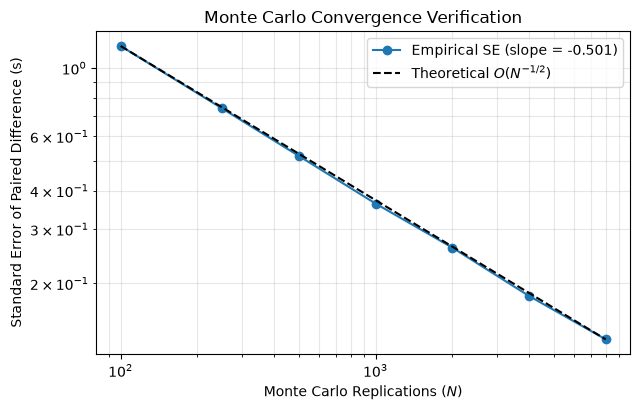

In [5]:
# Cell 5: Verification Suite (Core Checks + X2 Synthetic Recovery & N^(-1/2) Error Scaling)
# Check 1: Deterministic limit vs exact closed-form arithmetic sum (with fuel burn)
sc_zero = np.zeros((20, TOTAL_LAPS), dtype=np.int8)
t_det_sim = simulate_strategy_on_scenarios(
    [31], ["HARD", "HARD"], pit_loss_s=22.0, sc_matrix=sc_zero, sigma=0.0, sc_window=0
)
# Closed-form sum: 62*T_BASE + FUEL_EFFECT*(62*63/2) + 2 * BETA['HARD']*(30*31/2) + 22.0
expected_det = (
    TOTAL_LAPS * T_BASE
    + FUEL_EFFECT * (TOTAL_LAPS * (TOTAL_LAPS + 1) / 2)
    + 2 * (BETA["HARD"] * (30 * 31 / 2))
    + 22.0
)
assert abs(np.mean(t_det_sim) - expected_det) < 1e-9
assert np.std(t_det_sim) < 1e-12
print(f"[PASS] Check 1 (Deterministic Closed-Form): sim={np.mean(t_det_sim):.4f}s == exact={expected_det:.4f}s")

# Check 2: Analytic optimal pit lap vs grid search (symmetric HARD -> HARD -> p* = N/2 = 31)
grid_laps = list(range(15, 48))
grid_times = [deterministic_race_time([p], ["HARD", "HARD"], pit_loss_s=22.0) for p in grid_laps]
best_sym_lap = grid_laps[int(np.argmin(grid_times))]
assert best_sym_lap == TOTAL_LAPS // 2
print(f"[PASS] Check 2 (Analytic Optimal Pit Lap): grid argmin = lap {best_sym_lap} == N/2")

# Check 3: DTMC Stationary Distribution (matrix power + long-run empirical simulation)
p01_test, p10_test = 0.03, 1.0 / L_SC_MEAN
P_mat = np.array([[1.0 - p01_test, p01_test], [p10_test, 1.0 - p10_test]])
assert np.allclose(P_mat.sum(axis=1), 1.0)
pi_analytic = p01_test / (p01_test + p10_test)
pi_power = np.linalg.matrix_power(P_mat, 500)[0, 1]
assert abs(pi_power - pi_analytic) < 1e-6

# Empirical occupancy over 200,000 chain steps
rng_mc = np.random.default_rng(SEED)
u_chain = rng_mc.random(200_000)
s_curr, sc_count = 0, 0
for u_val in u_chain:
    s_curr = 1 if (s_curr == 0 and u_val < p01_test) else (0 if (s_curr == 1 and u_val < p10_test) else s_curr)
    sc_count += s_curr
pi_emp = sc_count / len(u_chain)
assert abs(pi_emp - pi_analytic) < 0.01
print(f"[PASS] Check 3 (DTMC Stationary): analytic={pi_analytic:.5f}, P^500={pi_power:.5f}, empirical={pi_emp:.5f}")

# Check 4: Parameter recovery from synthetic data (known ground truth)
rng_syn = np.random.default_rng(123)
n_syn = 3000
true_p = {"base": 99.0, "fuel": -0.055, "med_delta": -0.35, "beta_hard": 0.050, "beta_med_diff": 0.015, "sigma": 0.85}
syn_comp = rng_syn.choice(["HARD", "MEDIUM"], size=n_syn)
syn_lap = rng_syn.integers(2, 63, size=n_syn)
syn_age = rng_syn.integers(0, 30, size=n_syn)
syn_y = (
    true_p["base"]
    + true_p["fuel"] * syn_lap
    + np.where(syn_comp == "MEDIUM", true_p["med_delta"], 0.0)
    + (true_p["beta_hard"] + np.where(syn_comp == "MEDIUM", true_p["beta_med_diff"], 0.0)) * syn_age
    + rng_syn.normal(0.0, true_p["sigma"], size=n_syn)
)
syn_df = pd.DataFrame({"LapTime_s": syn_y, "LapNumber": syn_lap, "Compound": syn_comp, "TyreAge0": syn_age})
syn_fit = smf.ols("LapTime_s ~ LapNumber + C(Compound, Treatment(reference='HARD')) * TyreAge0", data=syn_df).fit()
assert abs(syn_fit.params["LapNumber"] - true_p["fuel"]) < 3 * syn_fit.bse["LapNumber"]
assert abs(syn_fit.params["TyreAge0"] - true_p["beta_hard"]) < 3 * syn_fit.bse["TyreAge0"]
assert abs(np.std(syn_fit.resid, ddof=1) - true_p["sigma"]) < 0.05
print(
    f"[PASS] Check 4 (Synthetic Parameter Recovery): fuel={syn_fit.params['LapNumber']:.4f} (true {true_p['fuel']}), "
    f"beta_H={syn_fit.params['TyreAge0']:.4f} (true {true_p['beta_hard']}), sigma={np.std(syn_fit.resid, ddof=1):.3f}"
)

# Check 5 (X2): Monte Carlo Standard Error Convergence Scaling ~ N^(-1/2)
Ns = np.array([100, 250, 500, 1000, 2000, 4000, 8000])
ses = []
for n_val in Ns:
    sc_n = generate_sc_scenarios(p_sc_deploy=0.025, n_sims=int(n_val), seed=SEED + int(n_val))
    d_n = (
        simulate_strategy_on_scenarios(*TWO_STOP, pit_loss_s=21.0, sc_matrix=sc_n, noise_seed=1000 + int(n_val))
        - simulate_strategy_on_scenarios(*ONE_STOP, pit_loss_s=21.0, sc_matrix=sc_n, noise_seed=2000 + int(n_val))
    )
    ses.append(np.std(d_n, ddof=1) / np.sqrt(n_val))

slope, intercept = np.polyfit(np.log10(Ns), np.log10(ses), 1)
assert abs(slope - (-0.5)) < 0.08, f"Expected slope ~ -0.5, got {slope:.3f}"
print(f"[PASS] Check 5 (MC Error Scaling N^-1/2): fitted log-log slope = {slope:.3f} (theoretical -0.500)")

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.loglog(Ns, ses, "o-", label=f"Empirical SE (slope = {slope:.3f})")
ref_line = ses[0] * (Ns / Ns[0]) ** (-0.5)
ax.loglog(Ns, ref_line, "--", color="black", label="Theoretical $O(N^{-1/2})$")
ax.set_xlabel("Monte Carlo Replications ($N$)")
ax.set_ylabel("Standard Error of Paired Difference (s)")
ax.set_title("Monte Carlo Convergence Verification")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "mc_convergence.png", dpi=200)
plt.show()

## 6. Experiments and Results

We sweep green-flag pit-stop loss (15–30 s) across Safety Car deployment probabilities and evaluate the two-car overtaking threshold extension (X3).

=== Break-Even Pit-Stop Loss (Paired CRN, N=4000) ===
p_SC=0.000/lap (P(>=1 SC)= 0.0%) | Opportunistic SC window (8 laps): 19.50 s | Rigid fixed-lap: 19.50 s
p_SC=0.015/lap (P(>=1 SC)=60.4%) | Opportunistic SC window (8 laps): 19.70 s | Rigid fixed-lap: 18.89 s
p_SC=0.030/lap (P(>=1 SC)=83.7%) | Opportunistic SC window (8 laps): 19.94 s | Rigid fixed-lap: 18.42 s
p_SC=0.045/lap (P(>=1 SC)=93.5%) | Opportunistic SC window (8 laps): 19.96 s | Rigid fixed-lap: 17.78 s


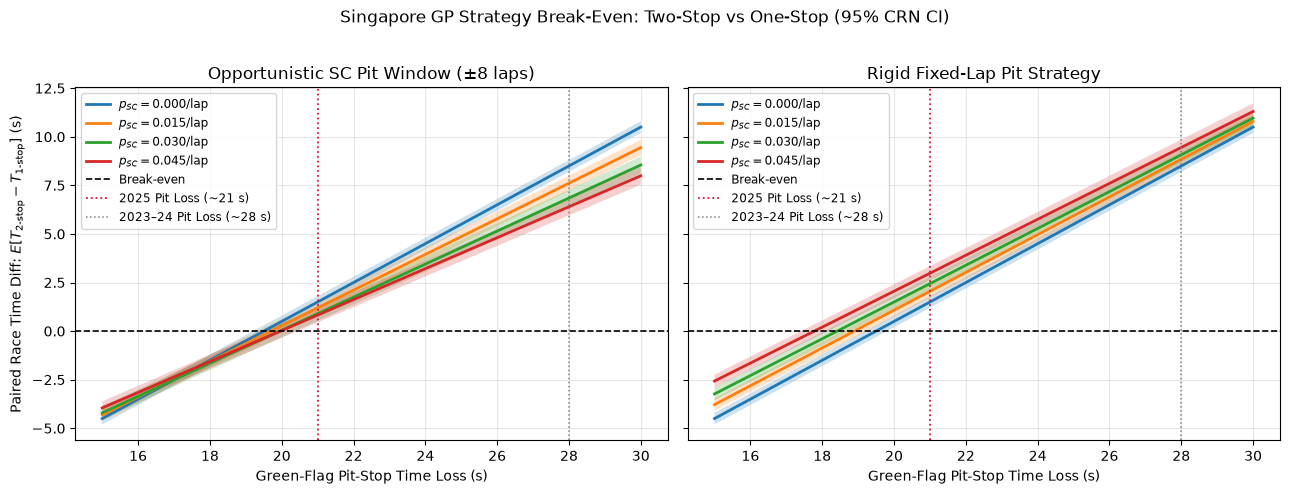

In [6]:
# Cell 6: Parameter Sweep — Pit-Stop Loss (15–30 s) vs Safety Car Probability (CRN)
pit_losses = np.linspace(15.0, 30.0, 31)
sc_probs = [0.000, 0.015, 0.030, 0.045]


def run_sweep(sc_window, n_sims=4000):
    rows = []
    for p_sc in sc_probs:
        sc_mat = generate_sc_scenarios(p_sc_deploy=p_sc, n_sims=n_sims, seed=SEED)
        p_any_sc = float(np.mean(sc_mat.any(axis=1)))
        for loss in pit_losses:
            t1 = simulate_strategy_on_scenarios(*ONE_STOP, pit_loss_s=loss, sc_matrix=sc_mat, sc_window=sc_window, noise_seed=101)
            t2 = simulate_strategy_on_scenarios(*TWO_STOP, pit_loss_s=loss, sc_matrix=sc_mat, sc_window=sc_window, noise_seed=202)
            diff = t2 - t1
            rows.append({
                "p_sc": p_sc,
                "p_any_sc": p_any_sc,
                "pit_loss": loss,
                "diff_mean": float(np.mean(diff)),
                "diff_ci95": float(1.96 * np.std(diff, ddof=1) / np.sqrt(n_sims)),
                "prob_2stop_wins": float(np.mean(diff < 0.0)),
            })
    return pd.DataFrame(rows)


def find_breakeven(grp):
    g = grp.sort_values("pit_loss")
    y, x = g["diff_mean"].to_numpy(), g["pit_loss"].to_numpy()
    if y[0] > 0:
        return np.nan  # 2-stop never wins in swept range
    if y[-1] < 0:
        return np.nan  # 2-stop always wins in swept range
    return float(np.interp(0.0, y, x))


df_opp = run_sweep(sc_window=8, n_sims=4000)
df_rig = run_sweep(sc_window=0, n_sims=4000)

print("=== Break-Even Pit-Stop Loss (Paired CRN, N=4000) ===")
for p_sc in sc_probs:
    g_o = df_opp[df_opp["p_sc"] == p_sc]
    g_r = df_rig[df_rig["p_sc"] == p_sc]
    p_any = g_o["p_any_sc"].iloc[0] * 100
    print(
        f"p_SC={p_sc:.3f}/lap (P(>=1 SC)={p_any:4.1f}%) | "
        f"Opportunistic SC window (8 laps): {find_breakeven(g_o):.2f} s | "
        f"Rigid fixed-lap: {find_breakeven(g_r):.2f} s"
    )

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, df_plot, title in [
    (axes[0], df_opp, "Opportunistic SC Pit Window (±8 laps)"),
    (axes[1], df_rig, "Rigid Fixed-Lap Pit Strategy"),
]:
    for p_sc, grp in df_plot.groupby("p_sc"):
        ax.plot(grp["pit_loss"], grp["diff_mean"], linewidth=2, label=f"$p_{{SC}}={p_sc:.3f}$/lap")
        ax.fill_between(
            grp["pit_loss"],
            grp["diff_mean"] - grp["diff_ci95"],
            grp["diff_mean"] + grp["diff_ci95"],
            alpha=0.22,
        )
    ax.axhline(0.0, color="black", linestyle="--", linewidth=1.2, label="Break-even")
    ax.axvline(21.0, color="crimson", linestyle=":", linewidth=1.3, label="2025 Pit Loss (~21 s)")
    ax.axvline(28.0, color="gray", linestyle=":", linewidth=1.1, label="2023–24 Pit Loss (~28 s)")
    ax.set_xlabel("Green-Flag Pit-Stop Time Loss (s)")
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8.5)

axes[0].set_ylabel("Paired Race Time Diff: $E[T_{2\\text{-stop}} - T_{1\\text{-stop}}]$ (s)")
plt.suptitle("Singapore GP Strategy Break-Even: Two-Stop vs One-Stop (95% CRN CI)", y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "breakeven_sweep.png", dpi=200, bbox_inches="tight")
plt.show()

[PASS] X3 Verification (Free-Air Limit): diff=+1.1194s == single-car +1.1194s | blocked=0.00

=== Two-Car Track Position Penalty at p_SC = 0.025/lap ===
  Free air (0.0 s)     | Break-even = 19.97 s | At 21 s: diff = +0.90 ± 0.42 s (avg blocked laps: 0.00)
  Threshold 1.0 s/lap  | Break-even = 19.10 s | At 21 s: diff = +1.63 ± 0.42 s (avg blocked laps: 1.26)
  Threshold 1.5 s/lap  | Break-even = 18.13 s | At 21 s: diff = +2.39 ± 0.42 s (avg blocked laps: 2.18)
  Threshold 2.0 s/lap  | Break-even = 16.67 s | At 21 s: diff = +3.49 ± 0.40 s (avg blocked laps: 3.22)


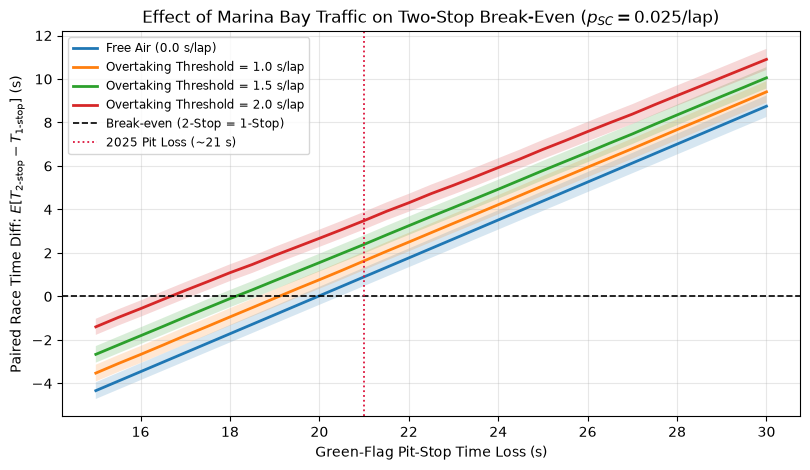

In [7]:
# Cell 7: Stretch Goal (X3) — Two-Car Track Position & Overtaking Threshold Model
def simulate_two_car_traffic(
    pit_loss_s,
    p_sc_deploy,
    overtake_threshold_s=1.2,
    dirty_air_gap_s=0.8,
    n_sims=3000,
    sc_window=8,
    seed=SEED,
    noise_seed_a=101,
    noise_seed_b=202,
):
    """
    Car A executes the optimal 1-stop; Car B executes the optimal 2-stop.
    When overtake_threshold_s > 0, if Car B trails Car A and closes into dirty_air_gap_s
    (pace_adv_b > 0) without meeting overtake_threshold_s, Car B is held at dirty_air_gap_s.
    """
    sc_mat = generate_sc_scenarios(p_sc_deploy=p_sc_deploy, n_sims=n_sims, seed=seed)
    noise_a = np.random.default_rng(noise_seed_a).normal(0.0, SIGMA, size=(n_sims, TOTAL_LAPS))
    noise_b = np.random.default_rng(noise_seed_b).normal(0.0, SIGMA, size=(n_sims, TOTAL_LAPS))

    def setup_car(targets, comps):
        return {
            "targets": np.array(targets, dtype=np.int16),
            "n_stops": len(targets),
            "delta": np.array([DELTA[c] for c in comps]),
            "beta": np.array([BETA[c] for c in comps]),
            "stint": np.zeros(n_sims, dtype=np.int8),
            "age": np.zeros(n_sims, dtype=np.float64),
            "cum_t": np.zeros(n_sims, dtype=np.float64),
        }

    car_a = setup_car(*ONE_STOP)
    car_b = setup_car(*TWO_STOP)
    laps_blocked = np.zeros(n_sims, dtype=np.int16)

    for lap in range(1, TOTAL_LAPS + 1):
        idx = lap - 1
        is_sc = sc_mat[:, idx] == 1

        def raw_lap(car, n_arr):
            g_t = (
                T_BASE
                + FUEL_EFFECT * lap
                + car["delta"][car["stint"]]
                + car["beta"][car["stint"]] * car["age"]
                + n_arr[:, idx]
            )
            lap_t = np.where(is_sc, T_SC, g_t)
            has_left = car["stint"] < car["n_stops"]
            nxt = car["targets"][np.minimum(car["stint"], car["n_stops"] - 1)]
            pit = (has_left & (lap == nxt)) | (
                has_left & is_sc & (sc_window > 0) & (lap >= nxt - sc_window) & (lap <= nxt) & (car["age"] >= 5)
            )
            eff_loss = np.where(is_sc, pit_loss_s * (1.0 - SC_PIT_DISCOUNT), pit_loss_s)
            return lap_t + np.where(pit, eff_loss, 0.0), pit

        ta, pit_a = raw_lap(car_a, noise_a)
        tb, pit_b = raw_lap(car_b, noise_b)

        if overtake_threshold_s > 0.0:
            b_behind = car_b["cum_t"] > car_a["cum_t"]
            pace_adv_b = ta - tb  # Positive only when Car B is faster and closing
            would_enter_dirty_air = (car_b["cum_t"] + tb) < (car_a["cum_t"] + ta + dirty_air_gap_s)
            blocked = (
                (~is_sc)
                & (~pit_a)
                & (~pit_b)
                & b_behind
                & would_enter_dirty_air
                & (pace_adv_b > 0.0)
                & (pace_adv_b < overtake_threshold_s)
            )
            tb_adj = np.where(
                blocked,
                np.maximum(tb, (car_a["cum_t"] + ta + dirty_air_gap_s) - car_b["cum_t"]),
                tb,
            )
            laps_blocked += blocked.astype(np.int16)
        else:
            tb_adj = tb

        car_a["cum_t"] += ta
        car_b["cum_t"] += tb_adj
        for car, pit in [(car_a, pit_a), (car_b, pit_b)]:
            car["stint"] = np.where(pit, car["stint"] + 1, car["stint"])
            car["age"] = np.where(pit, 0.0, car["age"] + 1.0)

    diff = car_b["cum_t"] - car_a["cum_t"]
    return float(np.mean(diff)), float(1.96 * np.std(diff, ddof=1) / np.sqrt(n_sims)), float(np.mean(laps_blocked))


# X3 Verification Check: Limiting case (overtake_threshold_s = 0.0) must match single-car model exactly
m_free, ci_free, blk_free = simulate_two_car_traffic(
    21.0, p_sc_deploy=0.025, overtake_threshold_s=0.0, n_sims=4000, seed=SEED, noise_seed_a=101, noise_seed_b=202
)
assert blk_free == 0.0, f"Expected 0 blocked laps in free air, got {blk_free}"
assert abs(m_free - float(np.mean(diff_ref))) < 1e-12, f"Mismatch vs single-car ref: {m_free} vs {np.mean(diff_ref)}"
print(f"[PASS] X3 Verification (Free-Air Limit): diff={m_free:+.4f}s == single-car {np.mean(diff_ref):+.4f}s | blocked={blk_free:.2f}")

# Traffic sweep across Marina Bay overtaking thresholds
thresholds = [0.0, 1.0, 1.5, 2.0]
traffic_curves = {}

print("\n=== Two-Car Track Position Penalty at p_SC = 0.025/lap ===")
for thr in thresholds:
    means_t, cis_t = [], []
    for loss in pit_losses:
        m, ci, _ = simulate_two_car_traffic(loss, p_sc_deploy=0.025, overtake_threshold_s=thr)
        means_t.append(m)
        cis_t.append(ci)
    traffic_curves[thr] = (np.array(means_t), np.array(cis_t))
    be_t = float(np.interp(0.0, means_t, pit_losses)) if means_t[0] <= 0 else np.nan
    m21, ci21, blk21 = simulate_two_car_traffic(21.0, p_sc_deploy=0.025, overtake_threshold_s=thr)
    label = "Free air (0.0 s)" if thr == 0.0 else f"Threshold {thr:.1f} s/lap"
    print(f"  {label:20s} | Break-even = {be_t:5.2f} s | At 21 s: diff = {m21:+.2f} ± {ci21:.2f} s (avg blocked laps: {blk21:.2f})")

# Save X3 figure for report and repository
fig, ax = plt.subplots(figsize=(8.2, 4.8))
for thr in thresholds:
    means_t, cis_t = traffic_curves[thr]
    lbl = "Free Air (0.0 s/lap)" if thr == 0.0 else f"Overtaking Threshold = {thr:.1f} s/lap"
    ax.plot(pit_losses, means_t, linewidth=2, label=lbl)
    ax.fill_between(pit_losses, means_t - cis_t, means_t + cis_t, alpha=0.18)

ax.axhline(0.0, color="black", linestyle="--", linewidth=1.2, label="Break-even (2-Stop = 1-Stop)")
ax.axvline(21.0, color="crimson", linestyle=":", linewidth=1.3, label="2025 Pit Loss (~21 s)")
ax.set_xlabel("Green-Flag Pit-Stop Time Loss (s)")
ax.set_ylabel("Paired Race Time Diff: $E[T_{2\\text{-stop}} - T_{1\\text{-stop}}]$ (s)")
ax.set_title("Effect of Marina Bay Traffic on Two-Stop Break-Even ($p_{SC} = 0.025$/lap)")
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8.5)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "traffic_penalty.png", dpi=200)
plt.show()

## 7. Discussion and Limitations

- **Key Finding:** Under zero-Safety-Car conditions, the two-stop breaks even only below 19.43 s pit-stop loss. Even with Marina Bay Safety Cars ($p_{\text{SC}} \approx 0.025\text{–}0.045$/lap), the expected break-even remains 19.7–20.1 s, explaining why teams stuck to one-stop strategies in 2025 (21 s pit loss).
- **Limitations:** Linear tyre degradation without thermal cliffing, fixed 50% SC pit-loss discount, and a two-car traffic abstraction rather than a full 20-car field.

## 8. References

1. A. M. Law, *Simulation Modeling and Analysis*, 5th ed. McGraw-Hill, 2015.
2. P. Glasserman, *Monte Carlo Methods in Financial Engineering*. Springer, 2003, doi: 10.1007/978-0-387-21617-1.
3. J. R. Norris, *Markov Chains*. Cambridge University Press, 1997, doi: 10.1017/CBO9780511810633.
4. FIA Formula One World Championship, *2023–2025 Singapore Grand Prix Official Timing Data*, accessed via FastF1 ([docs.fastf1.dev](https://docs.fastf1.dev/)).